In [23]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

from sklearn.preprocessing import label_binarize

In [24]:
import joblib

model = joblib.load("../models/best_model.pkl")

print("Model Loaded Successfully")

Model Loaded Successfully


In [25]:
X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv").iloc[:,0]

print(X_test.shape)

(6000, 113)


In [26]:
y_pred = model.predict(X_test)

In [28]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy :", accuracy)

Accuracy : 0.9746666666666667


In [29]:
precision = precision_score(

    y_test,

    y_pred,

    average="weighted"

)

print("Precision :", precision)

Precision : 0.9747597598920332


In [30]:
recall = recall_score(

    y_test,

    y_pred,

    average="weighted"

)

print("Recall :", recall)

Recall : 0.9746666666666667


In [31]:
f1 = f1_score(

    y_test,

    y_pred,

    average="weighted"

)

print("F1 Score :", f1)

F1 Score : 0.9746692316179312


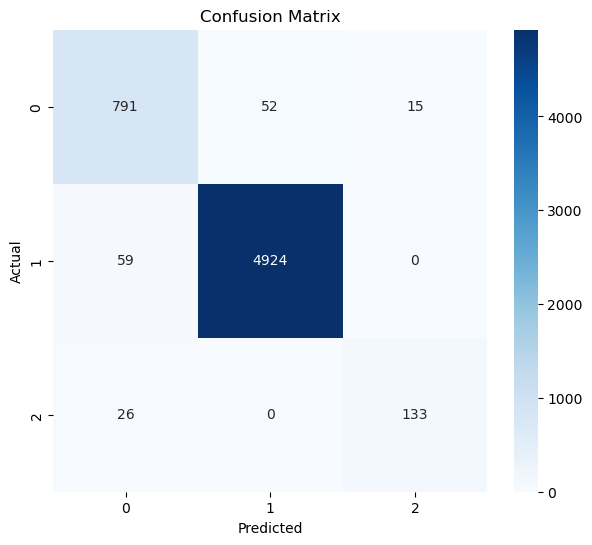

In [32]:
cm = confusion_matrix(

    y_test,

    y_pred

)

plt.figure(figsize=(7,6))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues"

)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [33]:
print(

classification_report(

    y_test,

    y_pred

)

)

              precision    recall  f1-score   support

           0       0.90      0.92      0.91       858
           1       0.99      0.99      0.99      4983
           2       0.90      0.84      0.87       159

    accuracy                           0.97      6000
   macro avg       0.93      0.92      0.92      6000
weighted avg       0.97      0.97      0.97      6000



In [34]:
classes = np.unique(y_test)

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

y_prob = model.predict_proba(X_test)
roc_auc = roc_auc_score(

    y_test_bin,

    y_prob,

    multi_class="ovr"

)

print("ROC AUC :", roc_auc)

ROC AUC : 0.9970756363673337


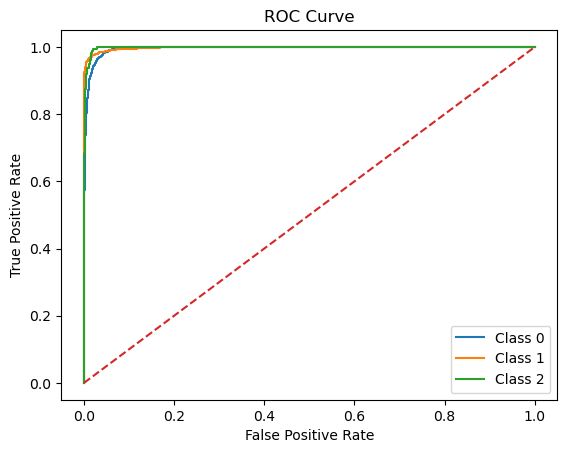

In [35]:
for i in range(len(classes)):

    fpr, tpr, _ = roc_curve(

        y_test_bin[:, i],

        y_prob[:, i]

    )

    plt.plot(

        fpr,

        tpr,

        label=f"Class {i}"

    )

plt.plot(

    [0,1],

    [0,1],

    "--"

)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [36]:
importance = pd.DataFrame({

    "Feature": X_test.columns,

    "Importance": model.feature_importances_

})

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

importance.head(20)

,Feature,Importance
11,Police_Distance_km,1450
8,Crime_Probability,1159
7,Hour,504
9,Theft_Reports,480
10,Harassment_Reports,415
107,CCTV_Yes,397
111,Road_Condition_Good,390
109,Shops_Open_Yes,388
110,Public_Transport_Yes,330
112,Road_Condition_Poor,312


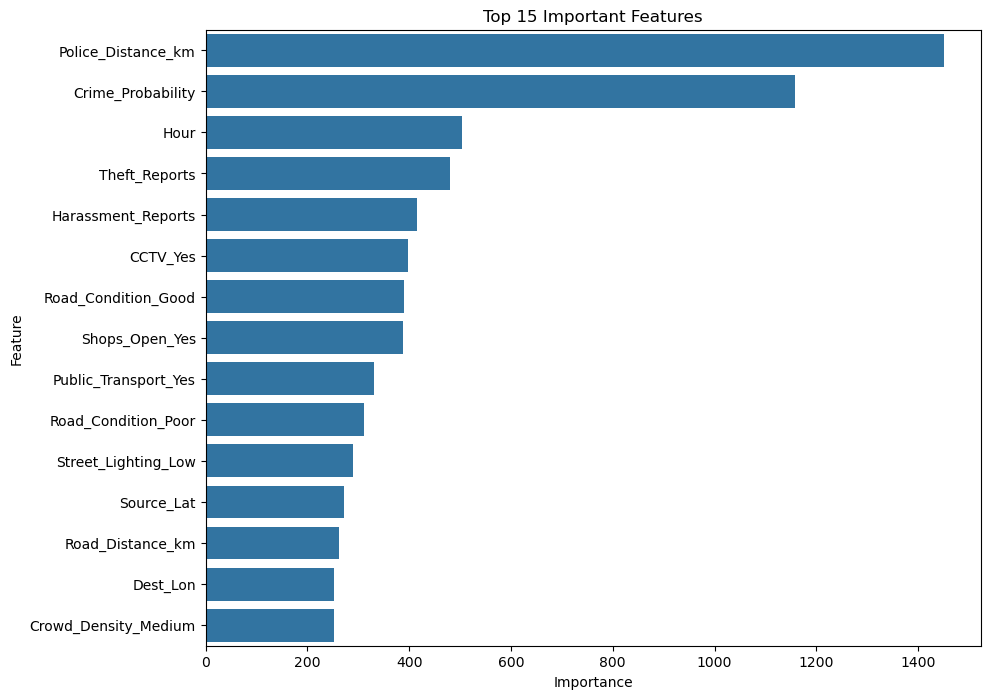

In [37]:
plt.figure(figsize=(10,8))

sns.barplot(

    data=importance.head(15),

    x="Importance",

    y="Feature"

)

plt.title("Top 15 Important Features")

plt.show()

In [39]:
import joblib

model = joblib.load("../models/best_model.pkl")

print(type(model))

<class 'lightgbm.sklearn.LGBMClassifier'>
